<a href="https://colab.research.google.com/github/donjperpetua/ML_ENG_HW1/blob/main/ML_ENG_HW3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Donald Perpetua | RIN: 662040925

In [3]:
#Problem 1

#Kmeans clustering for aircraft
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

df = pd.read_csv("aircraft_performance.csv")

df = df[["Aircraft", "Speed_kmh", "FuelFlow_kgph"]].copy()

df = df.dropna(subset=["Speed_kmh", "FuelFlow_kgph"])

df["Speed_kmh"] = pd.to_numeric(df["Speed_kmh"], errors="coerce")
df["FuelFlow_kgph"] = pd.to_numeric(df["FuelFlow_kgph"], errors="coerce")

df = df.dropna(subset=["Speed_kmh", "FuelFlow_kgph"])
df = df.reset_index(drop=True)

print("\nCleaned dataset:")
print(df)


Cleaned dataset:
                  Aircraft  Speed_kmh  FuelFlow_kgph
0               Cessna_172        226             24
1               Cessna_182        260             30
2               Piper_PA28        215             22
3             Diamond_DA40        240             26
4              Cirrus_SR20        250             29
5              Cirrus_SR22        300             36
6            Beech_Bonanza        285             34
7               Mooney_M20        290             33
8             Pilatus_PC12        520            780
9   Beechcraft_KingAir_200        540            900
10                  ATR_72        510            950
11              Dash8_Q400        610           1100
12            Embraer_E175        820           1600
13            Embraer_E190        830           1800
14                  CRJ700        780           1500
15                  CRJ900        800           1650
16             Airbus_A320        840           2600
17          Boeing_737_800  

In [4]:
features = ["Speed_kmh", "FuelFlow_kgph"]

X = df[features]

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

k = 2, silhouette score = 0.6404
k = 3, silhouette score = 0.6898
k = 4, silhouette score = 0.7945
k = 5, silhouette score = 0.7291
k = 6, silhouette score = 0.7440


<module 'matplotlib.pyplot' from '/usr/local/lib/python3.13/dist-packages/matplotlib/pyplot.py'>

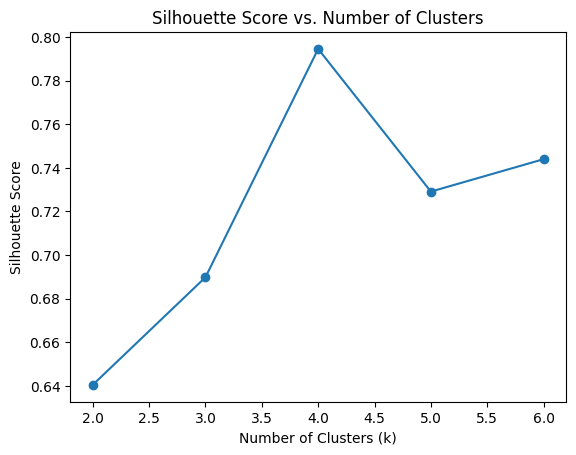

In [5]:
k_values = range(2, 7)
silhouette_scores = []

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, cluster_labels)

    silhouette_scores.append(score)

    print(f"k = {k}, silhouette score = {score:.4f}")

plt.plot(k_values, silhouette_scores, marker='o')
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score vs. Number of Clusters")
plt

In [6]:
best_k = 4
kmeans_final = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans_final.fit_predict(X_scaled)

print("\nAircraft cluster assignments:")
print(
    df[
        ["Aircraft", "Speed_kmh", "FuelFlow_kgph", "Cluster"]
    ].sort_values("Cluster")
)



Aircraft cluster assignments:
                  Aircraft  Speed_kmh  FuelFlow_kgph  Cluster
11              Dash8_Q400        610           1100        0
10                  ATR_72        510            950        0
9   Beechcraft_KingAir_200        540            900        0
8             Pilatus_PC12        520            780        0
26            KingAir_350i        575            980        0
24                 TBM_940        555            650        0
25                 PC12_NG        528            820        0
16             Airbus_A320        840           2600        1
19          Airbus_A321neo        840           2650        1
18         Boeing_737_MAX8        850           2550        1
17          Boeing_737_800        845           2700        1
27        Boeing_737_900ER        850           2850        1
28          Airbus_A320neo        840           2500        1
0               Cessna_172        226             24        2
2               Piper_PA28        215  


Cluster summary:
         Aircraft_Count  Mean_Speed_kmh  Mean_FuelFlow_kgph  Min_Speed_kmh  \
Cluster                                                                      
2                     8      258.250000           29.250000            215   
0                     7      548.285714          882.857143            510   
1                     6      844.166667         2641.666667            840   
3                     9      858.333333         1522.222222            780   

         Max_Speed_kmh  Min_FuelFlow_kgph  Max_FuelFlow_kgph  
Cluster                                                       
2                  300                 22                 36  
0                  610                650               1100  
1                  850               2500               2850  
3                  950               1100               1800  


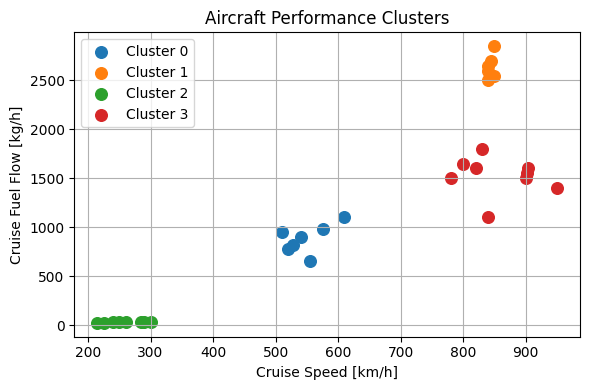

In [7]:
cluster_summary = (
    df.groupby("Cluster")
      .agg(
          Aircraft_Count=("Aircraft", "count"),
          Mean_Speed_kmh=("Speed_kmh", "mean"),
          Mean_FuelFlow_kgph=("FuelFlow_kgph", "mean"),
          Min_Speed_kmh=("Speed_kmh", "min"),
          Max_Speed_kmh=("Speed_kmh", "max"),
          Min_FuelFlow_kgph=("FuelFlow_kgph", "min"),
          Max_FuelFlow_kgph=("FuelFlow_kgph", "max")
      )
      .sort_values("Mean_Speed_kmh")
)

print("\nCluster summary:")
print(cluster_summary)

#scatter plot
plt.figure(figsize=(6, 4))

for cluster in sorted(df["Cluster"].unique()):

    cluster_data = df[df["Cluster"] == cluster]

    plt.scatter(
        cluster_data["Speed_kmh"],
        cluster_data["FuelFlow_kgph"],
        s=70,
        label=f"Cluster {cluster}"
    )


plt.xlabel("Cruise Speed [km/h]")
plt.ylabel("Cruise Fuel Flow [kg/h]")
plt.title("Aircraft Performance Clusters")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


First five rows:
        0        1
0  6.1101  17.5920
1  5.5277   9.1302
2  8.5186  13.6620
3  7.0032  11.8540
4  5.8598   6.8233

Dataset shape:
(97, 2)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 97 entries, 0 to 96
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   0       97 non-null     float64
 1   1       97 non-null     float64
dtypes: float64(2)
memory usage: 1.6 KB
None

Training with batch size = 1
Final parameters:
[[5.84678375]
 [4.68544564]]
Final objective:
4.481269923684125

Training with batch size = 5
Final parameters:
[[5.86196257]
 [4.60997223]]
Final objective:
4.477375254809855

Training with batch size = 10
Final parameters:
[[5.85535856]
 [4.59951317]]
Final objective:
4.47712392076444

Training with batch size = 20
Final parameters:
[[5.84292545]
 [4.59608575]]
Final objective:
4.476983194371154


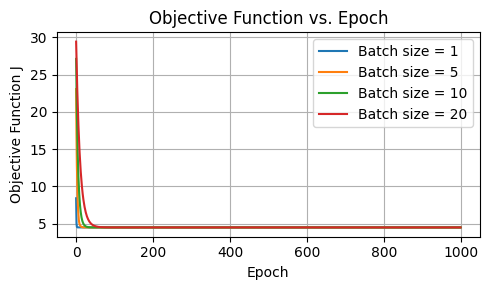

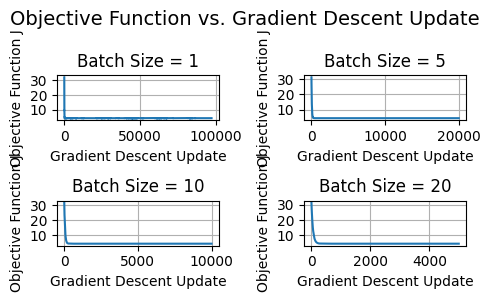


Predicted house prices
Batch size =  1: Predicted price = 15.3886
Batch size =  5: Predicted price = 15.2501
Batch size = 10: Predicted price = 15.2222
Batch size = 20: Predicted price = 15.2027


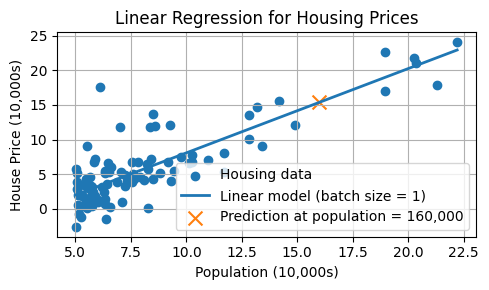

In [8]:
#Problem 2

#House Price Prediction via Mini-Batch Gradient Descent Regression
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data = pd.read_csv(
    "housing_prices.txt",
    header=None
)

print("First five rows:")
print(data.head())

print("\nDataset shape:")
print(data.shape)

print("\nDataset information:")
print(data.info())


X = data.iloc[:, 0].values.astype(float)
y = data.iloc[:, 1].values.astype(float)

X = X.reshape(-1, 1)
y = y.reshape(-1, 1)

#standardize
X_mean = np.mean(X, axis=0)
X_std = np.std(X, axis=0)

X_scaled = (X - X_mean) / X_std

X_design = np.column_stack(
    (np.ones(X_scaled.shape[0]), X_scaled)
)



#linear regression model

def predict(X, theta):
    """
    Linear regression prediction.
    X: Design matrix [1, x]
    theta: Model parameters [intercept, slope]
    """

    return X @ theta

def objective_function(X, y, theta):
    """
    Mean squared error objective function.
    J(theta) = (1 / 2m) * sum((prediction - y)^2)
    """

    m = len(y)

    predictions = predict(X, theta)

    error = predictions - y

    J = (1 / (2 * m)) * np.sum(error ** 2)

    return J

#mini-batch gradient descent

def mini_batch_gradient_descent(
    X,
    y,
    batch_size,
    learning_rate=0.01,
    epochs=1000,
    random_state=42
):
    """
    Train linear regression using mini-batch gradient descent.

    Parameters:
    X: ndarray
        Design matrix.
    y: ndarray
        Target values.

    batch_size  int
        Number of training samples used for each gradient update.
    learning_rate : float
        Gradient descent step size.
    epochs: int
        Number of passes through the complete dataset.
    random_state: int
        Random seed for reproducibility.

    Returns:
    theta: ndarray
        Learned model parameters.
    objective_history: list
        Objective function value after every update.
    """

    rng = np.random.default_rng(random_state)

    m = X.shape[0]

    #initialize parameters
    theta = np.zeros((X.shape[1], 1))

    objective_history = []
    epoch_objective_history = []

    for epoch in range(epochs):

        indices = rng.permutation(m)

        X_shuffled = X[indices]
        y_shuffled = y[indices]

        for start in range(0, m, batch_size):

            end = start + batch_size

            X_batch = X_shuffled[start:end]
            y_batch = y_shuffled[start:end]

            batch_m = X_batch.shape[0]

            predictions = predict(X_batch, theta)

            error = predictions - y_batch

            gradient = (1 / batch_m) * (
                X_batch.T @ error
            )

            theta = theta - learning_rate * gradient
            J = objective_function(X, y, theta)
            objective_history.append(J)

        J_epoch = objective_function(X, y, theta)

        epoch_objective_history.append(J_epoch)

    return theta, epoch_objective_history,objective_history



#train models using different batch sizes
batch_sizes = [1, 5, 10, 20]

results = {}

for batch_size in batch_sizes:

    print("\n" + "=" * 60)
    print(f"Training with batch size = {batch_size}")
    print("=" * 60)

    theta, epoch_objective_history, objective_history = mini_batch_gradient_descent(
        X_design,
        y,
        batch_size=batch_size,
        learning_rate=0.01,
        epochs=1000,
        random_state=42
    )

    results[batch_size] = {
        "theta": theta,
        "objective_epoch": epoch_objective_history,
        "objective": objective_history,
    }

    print("Final parameters:")
    print(theta)

    print("Final objective:")
    print(objective_history[-1])

plt.figure(figsize=(5, 3))

for batch_size in batch_sizes:

    epoch_objective_history = results[batch_size]["objective_epoch"]

    plt.plot(
        epoch_objective_history,
        label=f"Batch size = {batch_size}"
    )

plt.xlabel("Epoch")
plt.ylabel("Objective Function J")
plt.title("Objective Function vs. Epoch")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(5, 3))

axes = axes.flatten()

for i, batch_size in enumerate(batch_sizes):

    objective_history = results[batch_size]["objective"]

    axes[i].plot(
        objective_history
    )

    axes[i].set_title(f"Batch Size = {batch_size}")
    axes[i].set_xlabel("Gradient Descent Update")
    axes[i].set_ylabel("Objective Function J")
    axes[i].grid(True)

plt.suptitle(
    "Objective Function vs. Gradient Descent Update",
    fontsize=14
)

plt.tight_layout()
plt.show()

#predict the price for a city with population = 160,000 (16 * 10,000)
population = 16

#standardize the new population using the SAME mean and standard deviation
population_scaled = (
    population - X_mean[0]
) / X_std[0]

X_new = np.array([
    [1, population_scaled]
])


print("\n" + "=" * 60)
print("Predicted house prices")
print("=" * 60)

for batch_size in batch_sizes:

    theta = results[batch_size]["theta"]

    predicted_price = predict(
        X_new,
        theta
    )

    print(
        f"Batch size = {batch_size:2d}: "
        f"Predicted price = {predicted_price[0, 0]:.4f}"
    )

chosen_batch_size = 1

theta = results[chosen_batch_size]["theta"]

population_range = np.linspace(
    X.min(),
    X.max(),
    200
).reshape(-1, 1)

population_range_scaled = (
    population_range - X_mean
) / X_std

X_plot = np.column_stack(
    (
        np.ones(population_range_scaled.shape[0]),
        population_range_scaled[:, 0]
    )
)

price_predictions = predict(
    X_plot,
    theta
)

plt.figure(figsize=(5, 3))
plt.scatter(
    X[:, 0],
    y[:, 0],
    label="Housing data"
)

plt.plot(
    population_range[:, 0],
    price_predictions[:, 0],
    linewidth=2,
    label=f"Linear model (batch size = {chosen_batch_size})"
)
plt.scatter(
    [population],
    [predict(X_new, theta)[0, 0]],
    s=100,
    marker="x",
    label="Prediction at population = 160,000"
)
plt.xlabel("Population (10,000s)")
plt.ylabel("House Price (10,000s)")
plt.title("Linear Regression for Housing Prices")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Dataset shape:
(569, 30)

First five rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  wor

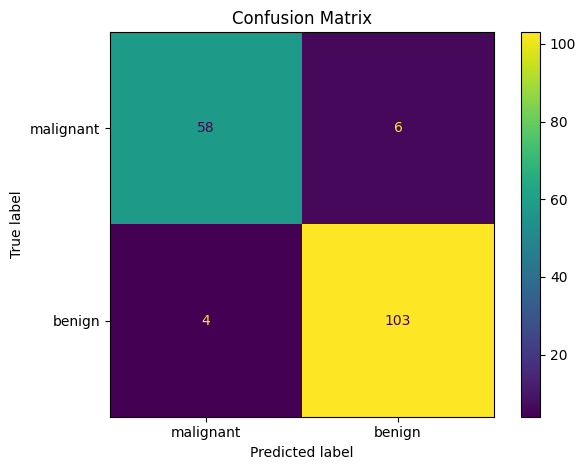

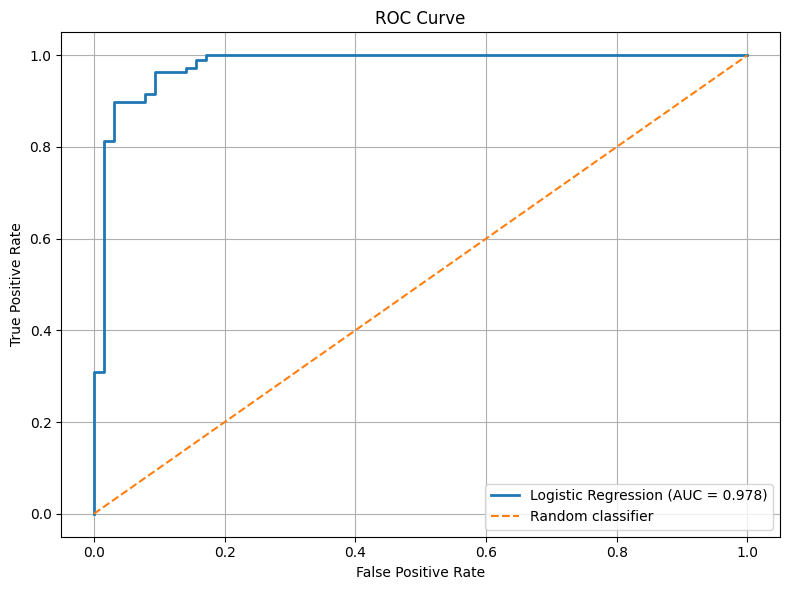

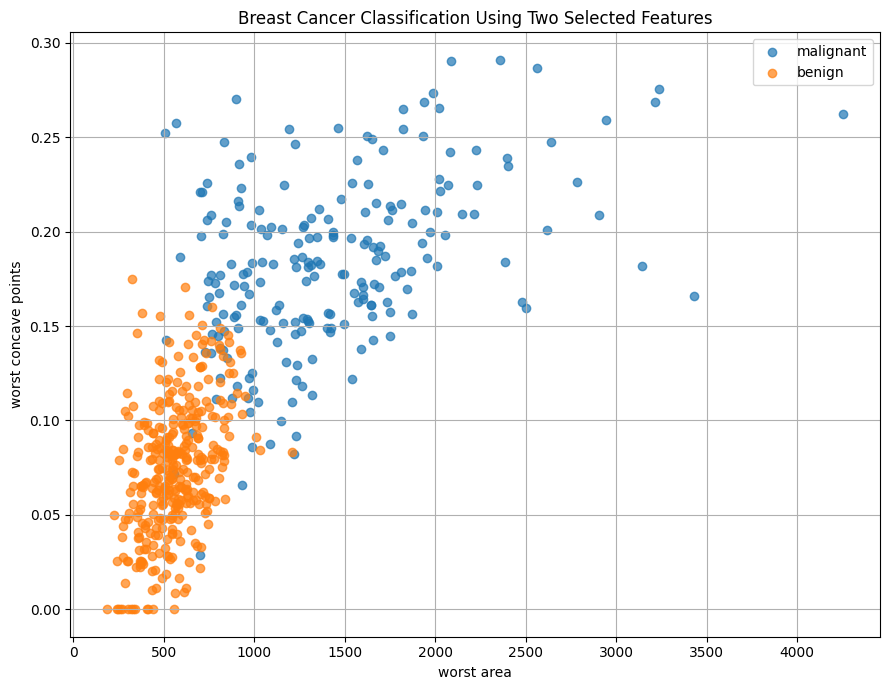

In [ ]:
#Problem 3

#Breast Cancer Classification
#Logistic Regression + Recursive Feature Elimination

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    roc_curve
)

cancer = load_breast_cancer()
X = pd.DataFrame(
    cancer.data,
    columns=cancer.feature_names
)
y = pd.Series(
    cancer.target,
    name="target"
)

print("Dataset shape:")
print(X.shape)

print("\nFirst five rows:")
print(X.head())

print("\nClass names:")
print(cancer.target_names)

print("\nClass distribution:")
print(y.value_counts())

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

#recursive feature elimination

rfe_model = Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "rfe",
        RFE(
            estimator=LogisticRegression(
                max_iter=5000,
                solver="liblinear"
            ),
            n_features_to_select=2,
            step=1
        )
    ),
    (
        "logistic_regression",
        LogisticRegression(
            max_iter=5000,
            solver="liblinear"
        )
    )
])


rfe_model.fit(
    X_train,
    y_train
)

rfe = rfe_model.named_steps["rfe"]

selected_features = X.columns[rfe.support_]

print("\n" + "=" * 60)
print("Selected Features")
print("=" * 60)

print(selected_features.tolist())

#RFE ranking
#ranking = 1 means the feature was selected.
#larger values mean the feature was eliminated earlier.

feature_ranking = pd.DataFrame({
    "Feature": X.columns,
    "RFE Ranking": rfe.ranking_
})

feature_ranking = feature_ranking.sort_values(
    "RFE Ranking"
)

print("\nRFE Feature Ranking:")
print(feature_ranking.to_string(index=False))

y_pred = rfe_model.predict(X_test)

#probability of class 1
y_prob = rfe_model.predict_proba(X_test)[:, 1]

#accuracy metrics
accuracy = accuracy_score(
    y_test,
    y_pred
)
precision = precision_score(
    y_test,
    y_pred
)
recall = recall_score(
    y_test,
    y_pred
)
f1 = f1_score(
    y_test,
    y_pred
)
#ROC score is true positive rate vs. false positive rate
#good evaluation metric for high-stakes classification
roc_auc = roc_auc_score(
    y_test,
    y_prob
)

print("\n" + "=" * 60)
print("Classification Results")
print("=" * 60)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"ROC AUC:   {roc_auc:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=cancer.target_names
    )
)

#Confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred
)
print("\nConfusion Matrix:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=cancer.target_names
).plot()

plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()


fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"Logistic Regression (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

#best features
feature_1 = selected_features[0]
feature_2 = selected_features[1]

plt.figure(figsize=(6, 4))

for target_value, target_name in enumerate(cancer.target_names):

    mask = y == target_value
    plt.scatter(
        X.loc[mask, feature_1],
        X.loc[mask, feature_2],
        label=target_name,
        alpha=0.7
    )
plt.xlabel(feature_1)
plt.ylabel(feature_2)

plt.title(
    f"Breast Cancer Classification Using Two Selected Features"
)
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
#Problem 4

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

data = pd.read_csv("housing_prices.txt", header=None)

X = data.iloc[:, 0].values.astype(float)
y = data.iloc[:, 1].values.astype(float)

X = X.reshape(-1, 1)
y = y.reshape(-1, 1)

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(1,)),
    tf.keras.layers.Dense(2, activation="relu"),
    tf.keras.layers.Dense(1)
])

learning_rate = 0.01

optimizer = tf.keras.optimizers.SGD(
    learning_rate=learning_rate
)

model.compile(
    optimizer=optimizer,
    loss="mse"
)

epochs = 1000

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=epochs,
    batch_size=1,
    verbose=0
)



Validation RMSE: 5.2461
Predicted price for population 165,000: $56,660.53


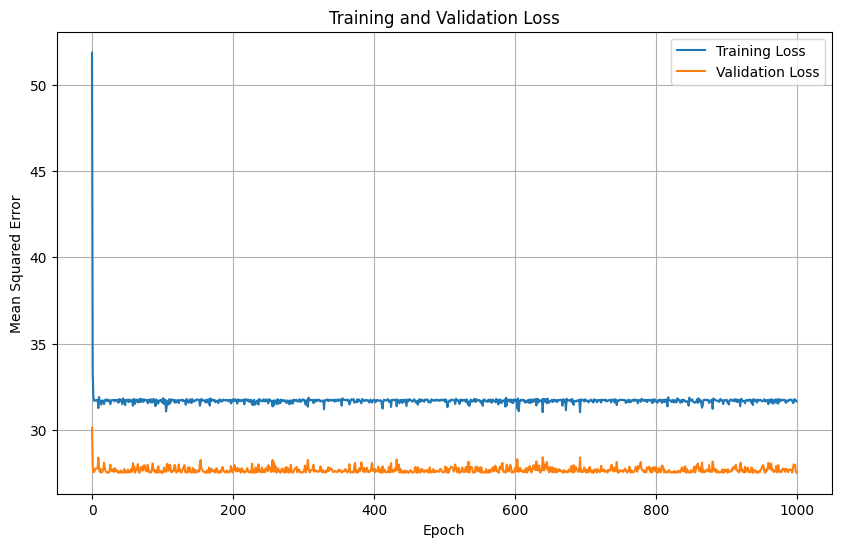

In [ ]:
y_val_pred = model.predict(X_val, verbose=0)

#calculate RMSE
rmse = np.sqrt(mean_squared_error(y_val, y_val_pred))

print(f"Validation RMSE: {rmse:.4f}")

population = np.array([[16.5]])

predicted_price = model.predict(population, verbose=0)[0, 0]

print(f"Predicted price for population 165,000: "
      f"${predicted_price * 10000:,.2f}")

#training and validation losses plots
plt.figure(figsize=(10, 6))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()